# mtDNA mutations-based lineage tracing

clone2vec doesn't care where the clonal labels come from, as long as the cells can be grouped into clones. Here we show it on [the dataset](https://www.nature.com/articles/s41587-020-0645-6) from Lareau et al., where clones are defined by somatic mtDNA mutations instead of a transgenic barcode, and the cells are profiled with mtscATAC-Seq instead of scRNA-Seq.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v
import bbknn

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

The dataset contains CD34+ progenitors differentiating *in vitro*, sampled at days 8, 14 and 20 from two independent cultures. Clones here are groups of cells sharing the same somatic mtDNA variants.

In [2]:
adata = c2v.datasets.Lareau_in_vitro()

using gene expression embedding


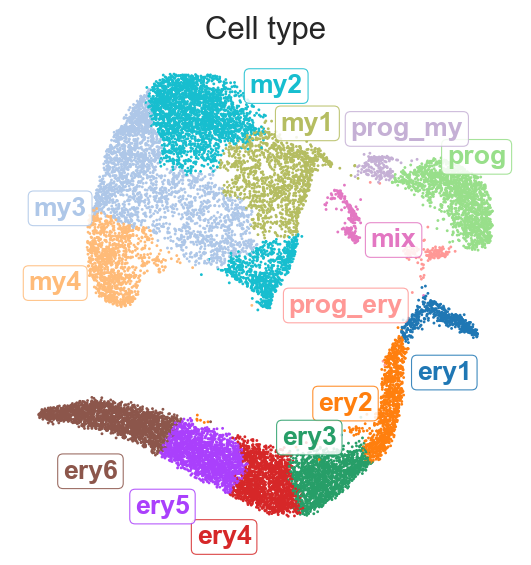

In [3]:
ax = sc.pl.embedding(
    adata,
    color="celltype",
    frameon=False,
    title="Cell type",
    show=False,
    basis="X_umap_original",
)

c2v.pl.fancy_legend(ax, center_loc=False, fontweight="bold", textsize=12)

In [4]:
clones = c2v.pp.clones_adata(
    adata,
    obs_name="clone",
    min_size=2,
    na_value="NA",
    fill_obs="celltype",
)

creating clone-level AnnData
    selected 197 clones (>= 2)
    finished (0:00:02): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label
     .uns['filtered_clones'] names and sizes of the clones smaller than min_size


## Clonal embedding

The only thing that changes for an ATAC dataset is the representation used for the nearest neighbours search: here it is the spectral embedding from `SnapATAC2` corrected with Harmony. Everything after that is exactly the same as for scRNA-Seq data.

In [5]:
c2v.tl.clonal_nn(
    adata,
    clones,
    use_rep="X_spectral_harmony",
)

computing clone-to-clone adjacency graph
    finished (0:00:44): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


In [6]:
c2v.tl.clone2vec(clones)

fitting clone2vec embeddings
    SG epochs:   3%|▎         | 17/500 [01:37<46:12,  5.74s/it, loss=4.0866, Δ=5.38e-05]
    early stopping at epoch 18
    finished (0:01:40): added
     .obsm['clone2vec'] embedding matrix
     .uns['clone2vec'] training details


In [7]:
c2v.pp.transfer_annotation(
    adata,
    clones,
    annotation_obs_adata="culture",
)

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['gex_culture'] categorical labels


Clones come from two independent cultures, so instead of `sc.pp.neighbors()` we build the clonal kNN-graph with `bbknn` — to make sure that the clusters we see are not just the cultures.

In [8]:
bbknn.bbknn(
    clones,
    batch_key="gex_culture",
    use_rep="clone2vec",
    neighbors_within_batch=5,
)

computing batch balanced neighbors
	finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)


In [9]:
sc.tl.umap(clones, min_dist=0.3)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:01)


In [10]:
sc.tl.leiden(clones, flavor="igraph", n_iterations=2)

running Leiden clustering
    finished: found 6 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


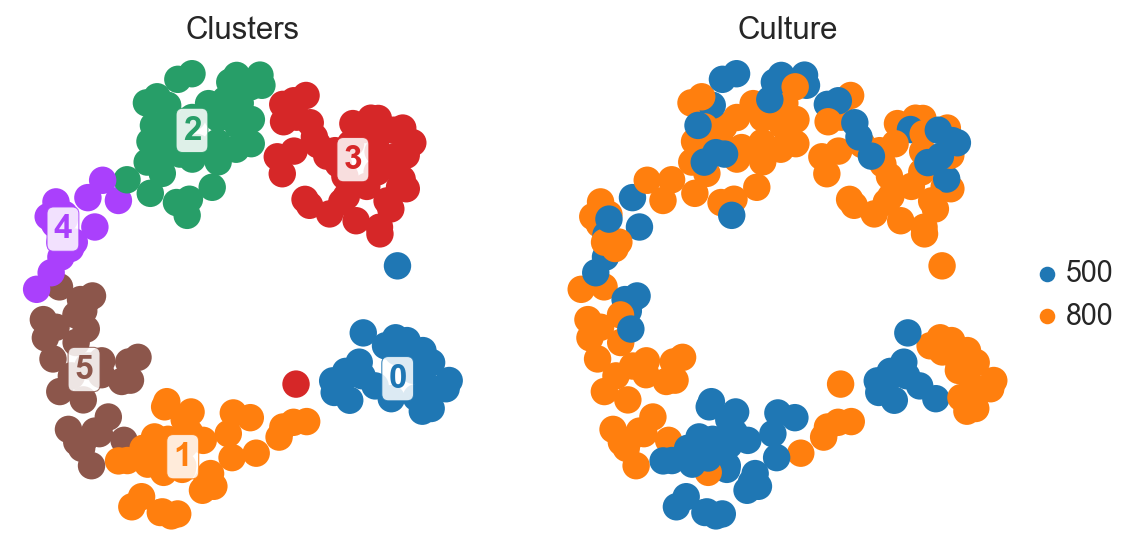

In [11]:
fig, axes = plt.subplots(ncols=2, figsize=(8, 4))

ax = sc.pl.umap(clones, color="leiden", title="Clusters", frameon=False, show=False, ax=axes[0])
c2v.pl.fancy_legend(axes[0], fontweight="bold", textsize=15, center_loc=True)

sc.pl.umap(clones, color="gex_culture", title="Culture", frameon=False, ax=axes[1])

## Fate biases

Clusters are easier to read through the cell type composition of their clones. Let's sum up the erythroid and the myeloid cell types, and look at them together with the progenitors.

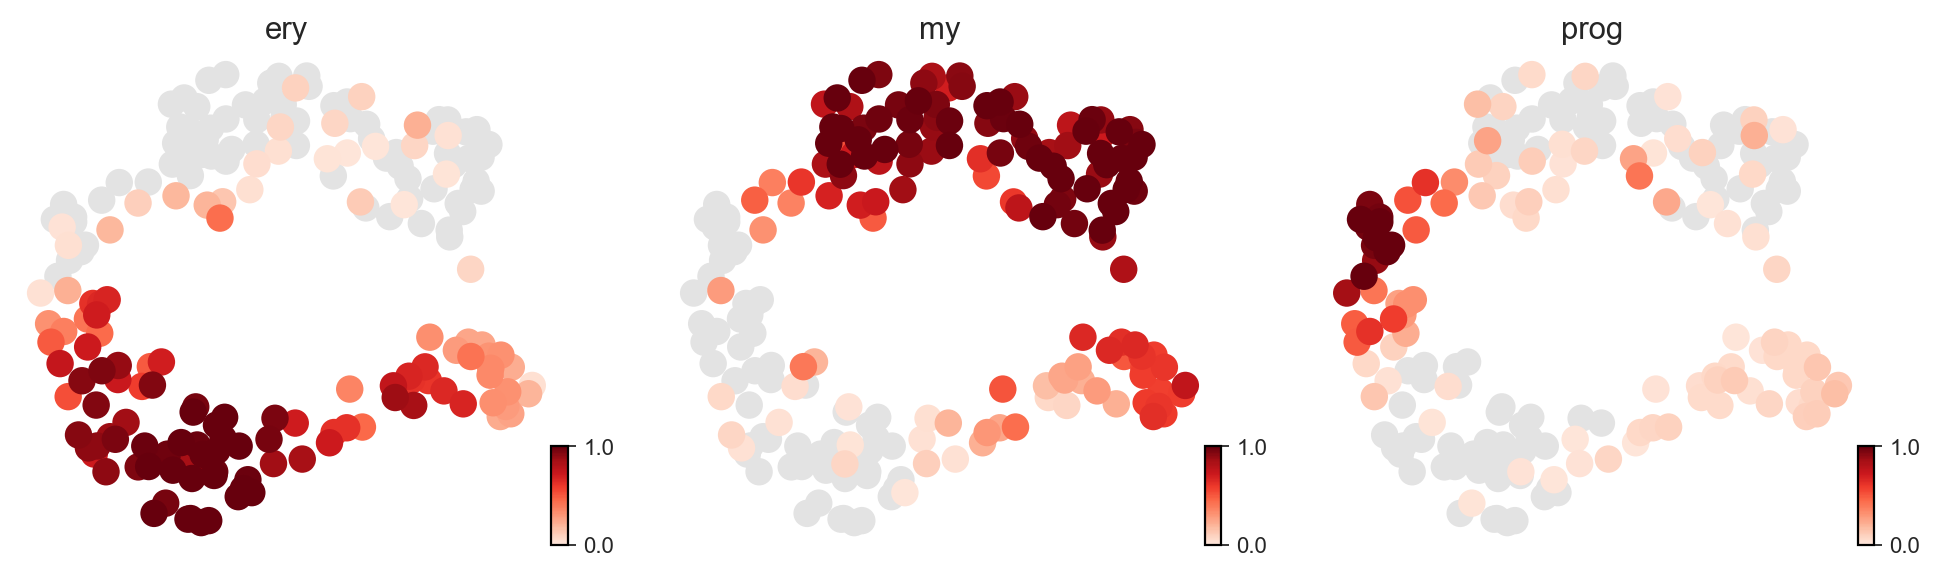

In [12]:
clones.obs["ery"] = clones[:, clones.var_names.str.startswith("ery")].X.sum(axis=1)
clones.obs["my"] = clones[:, clones.var_names.str.startswith("my")].X.sum(axis=1)

axes = sc.pl.umap(clones, color=["ery", "my", "prog"], cmap=c2v.pl.Reds, frameon=False, show=False)
c2v.pl.small_cbar(axes)

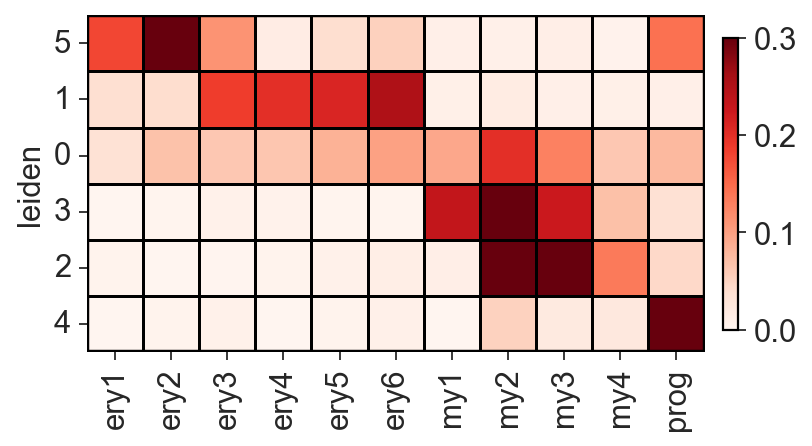

In [13]:
clean_vars = (
    list(clones.var_names[clones.var_names.str.startswith("ery")]) +
    list(clones.var_names[clones.var_names.str.startswith("my")]) +
    ["prog"]
)

ax = c2v.pl.heatmap(
    clones[:, clean_vars].to_df(layer="proportions").groupby(
        clones.obs.leiden, observed=False,
    ).mean().loc[["5", "1", "0", "3", "2", "4"]],
    cmap="Reds",
    vmin=0,
    vmax=0.3,
    sort_columns=False,
    figsize=(6, 4),
    show=False,
)

The same clusters can be transferred back to the cells, to see which parts of the chromatin accessibility embedding they occupy.

In [14]:
c2v.pp.transfer_annotation(adata, clones, annotation_obs_clones="leiden")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['c2v_leiden'] categorical labels


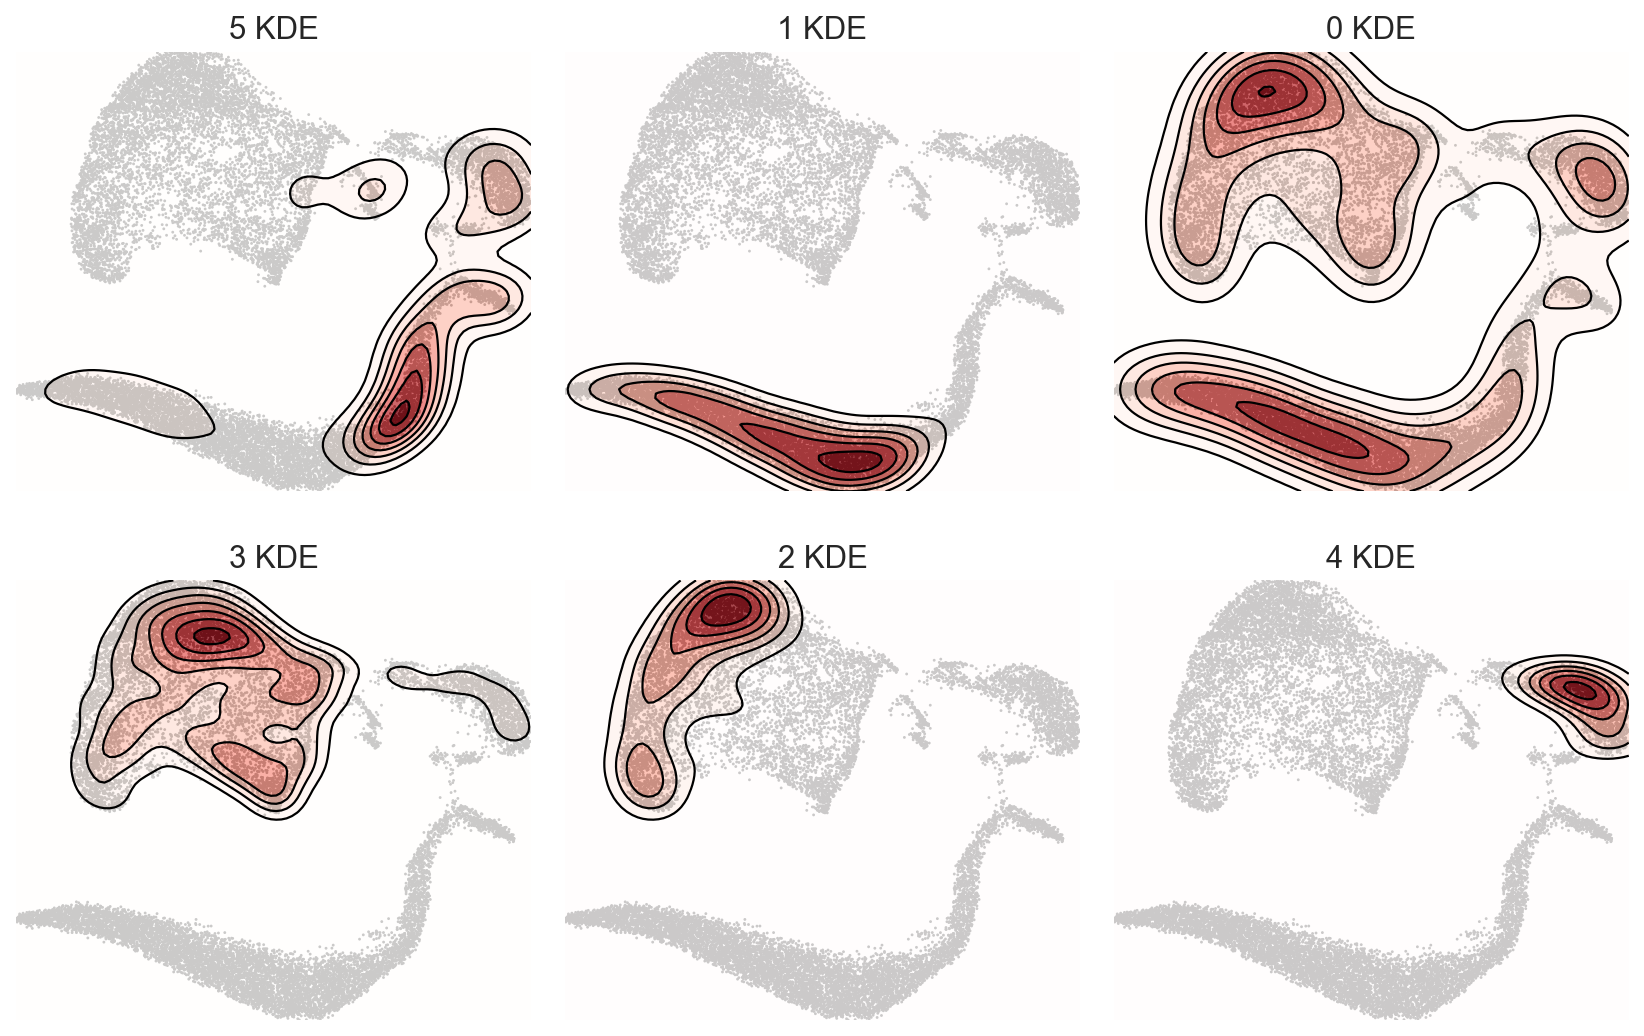

In [15]:
c2v.pl.group_kde(
    adata,
    groupby="c2v_leiden",
    basis="X_umap_original",
    groups=["5", "1", "0", "3", "2", "4"],
    bw_method=0.2,
    ncols=3,
)

And since the cells were collected at three timepoints, every clone can also be described by the days its cells come from.

In [16]:
clones.obsm["day"] = c2v.pp.recalc_composition(adata, clones, fill_obs="day").to_df()

recalculating clone composition
    finished (0:00:00): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of cells per clone
     .uns['fill_obs'] string label
     .obs and .obsm are copied from the original AnnData


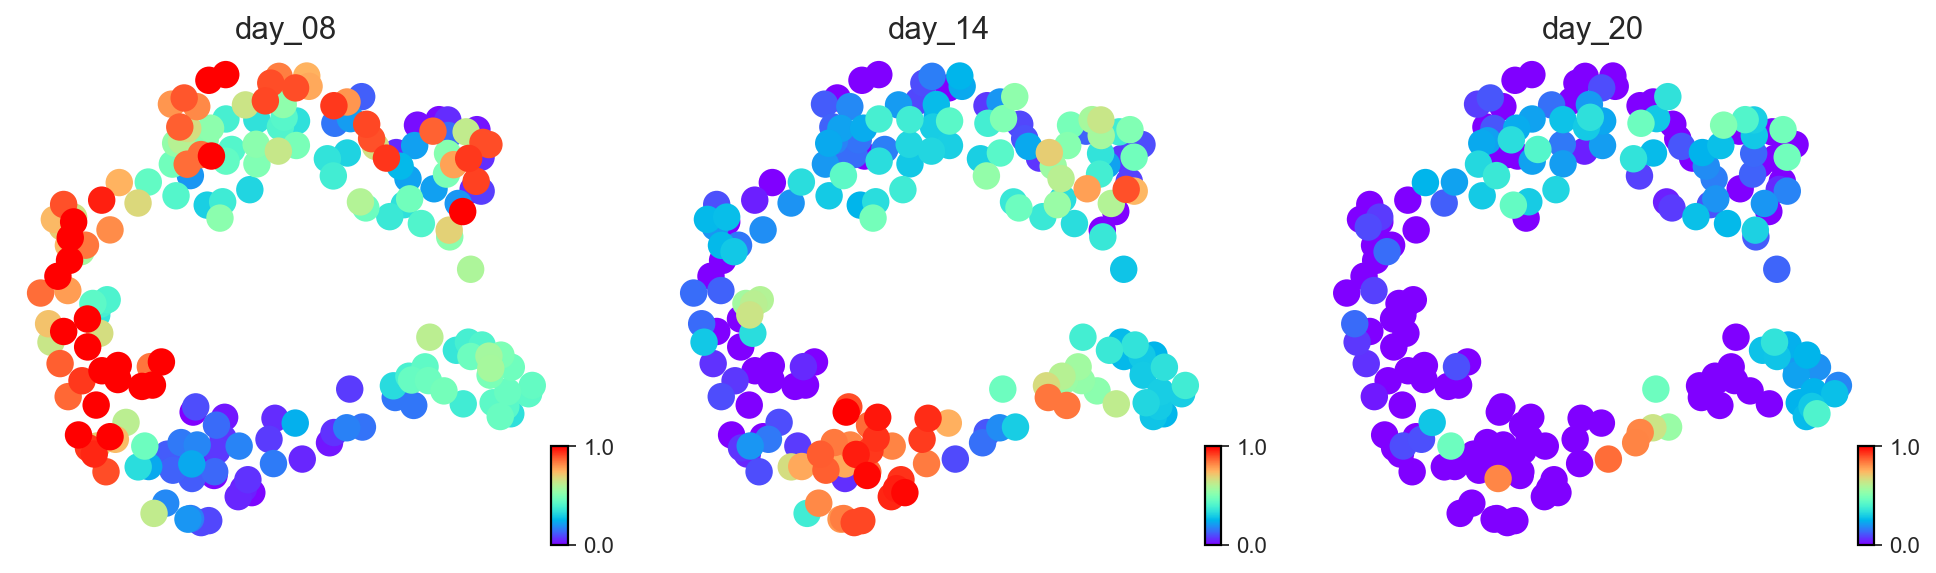

In [17]:
axes = c2v.pl.embedding(
    clones,
    obsm_name="day",
    obsm_component=["08", "14", "20"],
    vmax=1,
    cmap="rainbow",
    frameon=False,
    show=False,
)

c2v.pl.small_cbar(axes)

Clusters 1 and 5 are erythroid-biased, clusters 2 and 3 are myeloid-biased, cluster 4 is progenitor-biased, and cluster 0 consists of bipotent clones. Part of this structure is timing: cluster 5 is made mostly of day 8 cells, cluster 1 of day 14 ones, and the bipotent cluster 0 is the latest one. The difference between the two myeloid clusters, 2 and 3, is less obvious, and it is a good starting point for further analysis.

In any case, clone2vec works with mtDNA-based clones and chromatin accessibility in exactly the same way as with transgenic barcodes and gene expression.